DNN - Credential-based Intrusion Detection

1. Imports

In [7]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import shap

!pip install -q lime
import lime.lime_tabular

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_selection import mutual_info_classif

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

In [8]:
df = pd.read_csv('/kaggle/input/datasets/kadinawaf/credguard4/CredGuard_Io_Output1.csv')
print(df.shape)
print(df["label"].value_counts(dropna=False))

/tmp/ipykernel_50/1597533239.py:1: DtypeWarning: Columns (2,4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/kaggle/input/datasets/kadinawaf/credguard4/CredGuard_Io_Output1.csv')


(1003030, 22)
label
0.0    501998
1.0    501032
Name: count, dtype: int64


Value counts in label column:
label
0.0    501998
1.0    501032
Name: count, dtype: int64


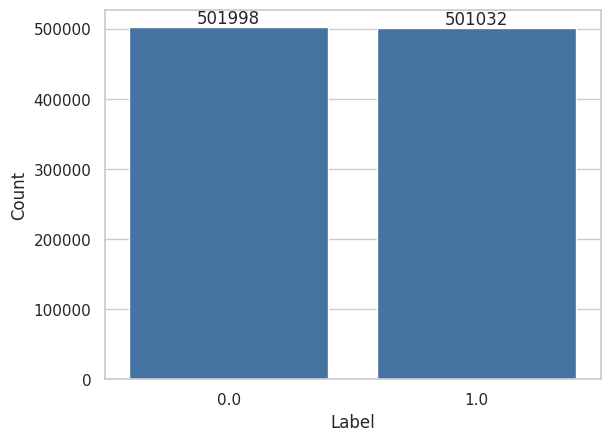

In [9]:
sns.set_theme(style="whitegrid")

ax = sns.countplot(x='label', data=df, color='#3572B0')
ax.bar_label(ax.containers[0])
plt.xlabel('Label', fontsize=12)
plt.ylabel('Count', fontsize=12)
print("Value counts in label column:")
print(df['label'].value_counts())

plt.show()

2. Configuration

In [10]:
IP_COL, USER_COL, LOC_COL, ASN_COL = "src_ip", "username", "location", "asn"
SEED = 42
keras.utils.set_random_seed(SEED)

Q = dict(v_fast=0.05, fast=0.20, v_reg=0.10, reg=0.30, failure=0.95)

FEATURES = [
    "hr", "dow", "is_wknd", "is_night",
    "p_len", "p_comp", "has_num", "has_spec", "p_score",
    "u_freq", "loc_freq", "asn_freq",
    "mean_iat", "std_iat", "iat_var", "is_v_fast", "is_fast", "is_reg", "is_v_reg",
    "tries", "fails", "fail_rate", "is_failure",
]

class_names = ["Normal", "Attack"]

assert len(FEATURES) == 23 and len(set(FEATURES)) == 23

3. Feature Engineering, Split and Model Builder Functions

In [11]:
def build_row_features(df):
    X = df.copy()
    ts = pd.to_datetime(X["timestamp"], format="mixed", errors="coerce")
    missing = ts.isna()
    X["hr"] = ts.dt.hour.fillna(0).astype("int8")
    X["dow"] = ts.dt.dayofweek.fillna(0).astype("int8")
    X["is_wknd"] = (X["dow"].isin([4, 5]) & ~missing).astype("int8")
    X["is_night"] = (((X["hr"] < 6) | (X["hr"] >= 23)) & ~missing).astype("int8")

    X["p_len"] = pd.to_numeric(X["password_length"], errors="coerce").fillna(0).astype("int16")
    X["p_comp"] = pd.to_numeric(X["password_complexity"], errors="coerce").fillna(0).astype("int16")
    pw = X["password"].astype(str)
    X["has_num"] = pw.str.contains(r"\d", regex=True).astype("int8")
    X["has_spec"] = pw.str.contains(r"[^\w\s]|_", regex=True).astype("int8")
    X["p_score"] = ((X["p_comp"] * X["p_len"]) / 10).astype("float32")

    X["mean_iat"] = pd.to_numeric(X["mean_iat"], errors="coerce").fillna(0).astype("float32")
    X["std_iat"] = pd.to_numeric(X["std_iat"], errors="coerce").fillna(0).astype("float32")
    X["iat_var"] = (X["std_iat"].astype("float64") ** 2).astype("float32")

    X["tries"] = pd.to_numeric(X["login_attempt"], errors="coerce").fillna(0).astype("int16")
    X["fails"] = pd.to_numeric(X["fail_attempt"], errors="coerce").fillna(0).astype("int16")
    X["fail_rate"] = pd.to_numeric(X["fail_ratio"], errors="coerce").fillna(0).astype("float32")

    X[USER_COL] = X[USER_COL].astype(str)
    X["target"] = X["label"].astype("int8")
    return X


def group_split(X_all):
    g1 = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
    tr, tmp = next(g1.split(X_all, X_all["target"], groups=X_all[IP_COL]))
    train, temp = X_all.iloc[tr].copy(), X_all.iloc[tmp].copy()
    g2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=SEED)
    va, te = next(g2.split(temp, temp["target"], groups=temp[IP_COL]))
    val, test = temp.iloc[va].copy(), temp.iloc[te].copy()
    a, b, c = set(train[IP_COL]), set(val[IP_COL]), set(test[IP_COL])
    assert a.isdisjoint(b) and a.isdisjoint(c) and b.isdisjoint(c), "IP overlap!"
    return train, val, test


class TrainFitted:
    def fit(self, train):
        self.u_map = train[USER_COL].value_counts(normalize=True)
        self.loc_map = train[LOC_COL].value_counts(normalize=True)
        self.asn_map = train[ASN_COL].value_counts(normalize=True)
        q = lambda c, p: float(train[c].quantile(p))
        self.t = dict(v_fast=q("mean_iat", Q["v_fast"]), fast=q("mean_iat", Q["fast"]),
                      v_reg=q("std_iat", Q["v_reg"]), reg=q("std_iat", Q["reg"]),
                      failure=q("fail_rate", Q["failure"]))
        return self

    def transform(self, df):
        d, t = df.copy(), self.t
        d["u_freq"] = d[USER_COL].map(self.u_map).fillna(0).astype("float32")
        d["loc_freq"] = d[LOC_COL].map(self.loc_map).fillna(0).astype("float32")
        d["asn_freq"] = d[ASN_COL].map(self.asn_map).fillna(0).astype("float32")
        d["is_v_fast"] = (d["mean_iat"] < t["v_fast"]).astype("int8")
        d["is_fast"] = ((d["mean_iat"] >= t["v_fast"]) & (d["mean_iat"] < t["fast"])).astype("int8")
        d["is_v_reg"] = (d["std_iat"] < t["v_reg"]).astype("int8")
        d["is_reg"] = ((d["std_iat"] >= t["v_reg"]) & (d["std_iat"] < t["reg"])).astype("int8")
        d["is_failure"] = (d["fail_rate"] >= t["failure"]).astype("int8")

        return d

def featurize(train, val, test):
    st = TrainFitted().fit(train)
    tr, va, te = st.transform(train), st.transform(val), st.transform(test)
    return dict(X_train=tr[FEATURES], y_train=tr["target"],
                X_val=va[FEATURES], y_val=va["target"],
                X_test=te[FEATURES], y_test=te["target"])


def build_dnn(input_dim, hidden=(128, 64, 32), dropout=0.3, lr=1e-3):
    """Fully-connected binary DNN."""
    inputs = keras.Input(shape=(input_dim,))
    x = inputs
    for units in hidden:
        x = layers.Dense(units, activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")]
    )
    return model

4. Data Preparation and Scaling

In [12]:
X_all = build_row_features(df)
train, val, test = group_split(X_all)
S = featurize(train, val, test)

X_train, y_train = S["X_train"], S["y_train"]
X_val,   y_val   = S["X_val"],   S["y_val"]
X_test,  y_test  = S["X_test"],  S["y_test"]

scaler = StandardScaler().fit(X_train)

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_val_scaled   = pd.DataFrame(scaler.transform(X_val),   columns=FEATURES, index=X_val.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=FEATURES, index=X_test.index)

# DNN works on 2D arrays
X_train_dnn = X_train_scaled.values.astype("float32")
X_val_dnn   = X_val_scaled.values.astype("float32")
X_test_dnn  = X_test_scaled.values.astype("float32")

y_train_arr = y_train.values.astype("float32")
y_val_arr   = y_val.values.astype("float32")
y_test_arr  = y_test.values.astype("float32")

cw = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train.values)
class_weight_dict = {0: float(cw[0]), 1: float(cw[1])}

print(X_train_dnn.shape, X_val_dnn.shape, X_test_dnn.shape)
print(y_train.value_counts())
print("Class weights:", class_weight_dict)

(755190, 23) (129328, 23) (118512, 23)
target
1    388585
0    366605
Name: count, dtype: int64
Class weights: {0: 1.0299777689884209, 1: 0.9717178995586552}


5. Split Sizes

In [13]:
splits = {"Train": train, "Validation": val, "Test": test}
sizes_df = pd.DataFrame({
    "Split": list(splits.keys()),
    "Rows": [len(d) for d in splits.values()],
    "Unique IPs": [d[IP_COL].nunique() for d in splits.values()],
    "Normal": [int((d["target"] == 0).sum()) for d in splits.values()],
    "Attack": [int((d["target"] == 1).sum()) for d in splits.values()],
})
sizes_df["Attack %"] = (sizes_df["Attack"] / sizes_df["Rows"] * 100).round(2)
sizes_df

,Split,Rows,Unique IPs,Normal,Attack,Attack %
0,Train,755190,60122,366605,388585,51.46
1,Validation,129328,12883,68372,60956,47.13
2,Test,118512,12884,67021,51491,43.45


6. Build DNN Model

In [14]:
dnn = build_dnn(input_dim=X_train_dnn.shape[1], hidden=(128, 64, 32), dropout=0.3, lr=1e-3)

E0000 00:00:1795024217.746058      50 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


7. Model Summary, Compile and Callbacks

In [15]:
print("\n DNN Architecture:")
dnn.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.00001, verbose=1)
checkpoint = ModelCheckpoint('best_dnn_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [early_stop, reduce_lr, checkpoint]


 DNN Architecture:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 23)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,337 (56.00 KB)

 Trainable params: 13,889 (54.25 KB)

 Non-trainable params: 448 (1.75 KB)

8. Train DNN Model

In [16]:
history = dnn.fit(
    X_train_dnn, y_train_arr,
    validation_data=(X_val_dnn, y_val_arr),
    epochs=50,
    batch_size=512,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)
print("Epochs trained:", len(history.history["loss"]))

Epoch 1/50
1472/1475 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7450 - auc: 0.8343 - loss: 0.4935
Epoch 1: val_accuracy improved from None to 0.77849, saving model to best_dnn_model.keras

Epoch 1: finished saving model to best_dnn_model.keras
1475/1475 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.7738 - auc: 0.8683 - loss: 0.4397 - val_accuracy: 0.7785 - val_auc: 0.8932 - val_loss: 0.3944 - learning_rate: 0.0010
Epoch 2/50
1472/1475 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7981 - auc: 0.8937 - loss: 0.3912
Epoch 2: val_accuracy improved from 0.77849 to 0.78235, saving model to best_dnn_model.keras

Epoch 2: finished saving model to best_dnn_model.keras
1475/1475 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.7998 - auc: 0.8951 - loss: 0.3880 - val_accuracy: 0.7824 - val_auc: 0.8971 - val_loss: 0.3839 - learning_rate: 0.0010
Epoch 3/50
1473/1475 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8033 - auc: 0.8996 - loss: 0.3785
Epoch 3: val_accuracy improved from 0.78235 to 

 9. Training History

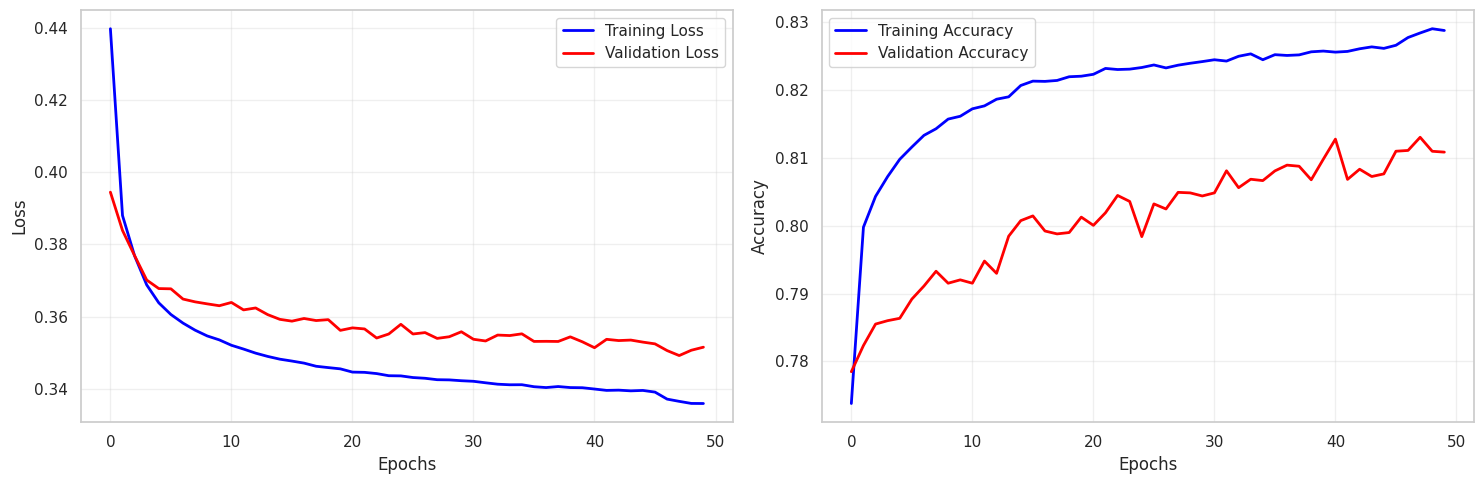

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history.history['loss'], label='Training Loss', color='blue', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='red', linewidth=2)
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', color='red', linewidth=2)
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

10. Predictions and Threshold Selection (validation only)

In [18]:
p_train = dnn.predict(X_train_dnn, batch_size=4096, verbose=0).ravel()
p_val   = dnn.predict(X_val_dnn,   batch_size=4096, verbose=0).ravel()
p_test  = dnn.predict(X_test_dnn,  batch_size=4096, verbose=0).ravel()

grid = np.arange(0.30, 0.701, 0.01)
f1_grid = [f1_score(y_val, (p_val >= t).astype(int)) for t in grid]
thr = float(grid[int(np.argmax(f1_grid))])
print("Selected threshold:", round(thr, 2))

Selected threshold: 0.47


11. Final Results Table

In [19]:
def result_row(name, y, p, t):
    pred = (p >= t).astype(int)
    return {
        "Experiment": name,
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 2),
        "Precision (%)": round(precision_score(y, pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y, pred, zero_division=0) * 100, 2),
        "F1 (%)": round(f1_score(y, pred, zero_division=0) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y, p), 4),
    }

results_df = pd.DataFrame([
    result_row("Validation (threshold 0.50)", y_val, p_val, 0.5),
    result_row("Test (threshold 0.50)", y_test, p_test, 0.5),
    result_row(f"Validation (threshold {thr:.2f})", y_val, p_val, thr),
    result_row(f"Test (threshold {thr:.2f})", y_test, p_test, thr),
])

sizes_df.to_csv("dnn_split_sizes.csv", index=False)
results_df.to_csv("dnn_final_results.csv", index=False)
results_df

,Experiment,Accuracy (%),Precision (%),Recall (%),F1 (%),ROC-AUC
0,Validation (threshold 0.50),81.30,77.97,84.09,80.92,0.9130
1,Test (threshold 0.50),77.40,73.77,74.44,74.11,0.8787
2,Validation (threshold 0.47),81.13,76.19,87.22,81.33,0.9130
3,Test (threshold 0.47),77.26,71.91,78.21,74.92,0.8787


12. Model Evaluation

In [20]:
y_train_pred = (p_train >= thr).astype(int)
y_val_pred   = (p_val   >= thr).astype(int)
y_test_pred  = (p_test  >= thr).astype(int)

train_acc = accuracy_score(y_train, y_train_pred)
val_acc   = accuracy_score(y_val,   y_val_pred)
test_acc  = accuracy_score(y_test,  y_test_pred)
test_f1   = f1_score(y_test, y_test_pred, average='weighted')

print("Accuracy Scores:")
print(f"  • Training: {train_acc:.4f}")
print(f"  • Test: {test_acc:.4f}")
print(f"  • Validation: {val_acc:.4f}")
print(f"  • F1-Score (Weighted): {test_f1:.4f}")

print("Unique in y_test:", np.unique(y_test))
print("Unique in y_test_pred:", np.unique(y_test_pred))

Accuracy Scores:
  • Training: 0.8358
  • Test: 0.7726
  • Validation: 0.8113
  • F1-Score (Weighted): 0.7734
Unique in y_test: [0 1]
Unique in y_test_pred: [0 1]


13. Accuracy Comparison

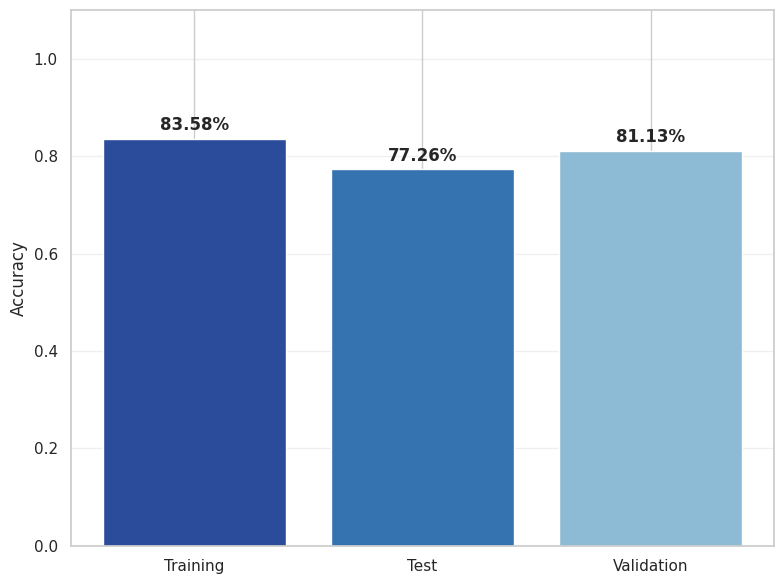

In [21]:
plt.figure(figsize=(8, 6))
accuracies = [train_acc, test_acc, val_acc]
bars = plt.bar(['Training', 'Test', 'Validation'], accuracies,
               color=['#2B4C9B', '#3572B0', '#8DBBD5'])

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
             f'{acc:.2%}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.ylim(0, 1.1)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

14. Class Distribution

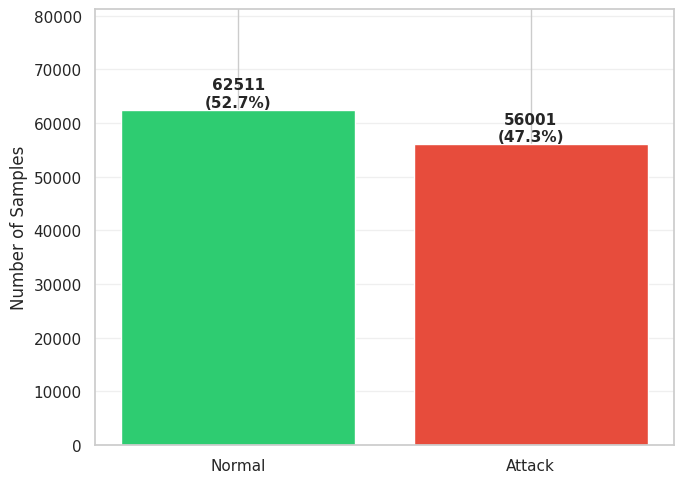

In [22]:
plt.figure(figsize=(7, 5))
colors = ['#2ECC71', '#E74C3C']
class_counts = pd.Series(y_test_pred.flatten()).value_counts().sort_index()
total = len(y_test_pred)
bars = plt.bar(class_names, [class_counts.get(i, 0) for i in range(2)], color=colors)
plt.ylim(0, class_counts.max() * 1.3)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}\n({height/total*100:.1f}%)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.ylabel('Number of Samples', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

15. Mutual Information

Top 15 Mutual Information Scores:
       Feature  MI_Score
11    asn_freq  0.266377
10    loc_freq  0.193346
13     std_iat  0.191986
12    mean_iat  0.188815
21   fail_rate  0.132310
9       u_freq  0.127680
20       fails  0.108089
14     iat_var  0.097292
19       tries  0.074336
22  is_failure  0.047422
17      is_reg  0.040763
0           hr  0.031357
6      has_num  0.031162
3     is_night  0.018486
16     is_fast  0.016429


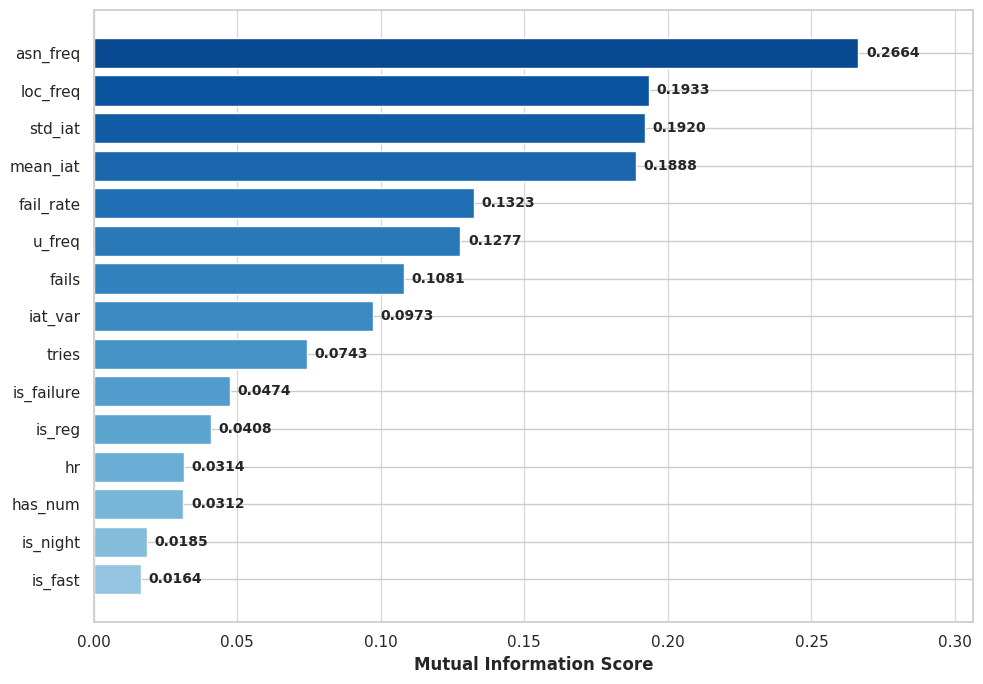

In [23]:
feature_columns = X_train.columns
X_train_df = X_train.fillna(0)

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_train_df), size=min(20000, len(X_train_df)), replace=False)
X_sample = X_train_df.iloc[sample_idx]
y_sample = y_train.iloc[sample_idx]

mi_scores = mutual_info_classif(X_sample, y_sample, random_state=42)
mi_df = pd.DataFrame({'Feature': feature_columns, 'MI_Score': mi_scores}).sort_values(by='MI_Score', ascending=False)

print("Top 15 Mutual Information Scores:")
print(mi_df.head(15))

plt.figure(figsize=(10, 7))
top_15_mi = mi_df.head(15)
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_15_mi)))

bars = plt.barh(range(len(top_15_mi)), top_15_mi['MI_Score'].values, color=colors[::-1])

plt.grid(visible=True, axis='x', color='black', linestyle='-', alpha=0.15)
plt.yticks(range(len(top_15_mi)), top_15_mi['Feature'].values)
plt.xlabel('Mutual Information Score', fontsize=12, fontweight='bold')

plt.gca().invert_yaxis()
plt.xlim(0, top_15_mi['MI_Score'].max() * 1.15)

for i, (bar, val) in enumerate(zip(bars, top_15_mi['MI_Score'].values)):
    plt.text(
        bar.get_width() + (top_15_mi['MI_Score'].max() * 0.01),
        bar.get_y() + bar.get_height()/2,
        f'{val:.4f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

16. Feature Importance (Permutation on Validation)

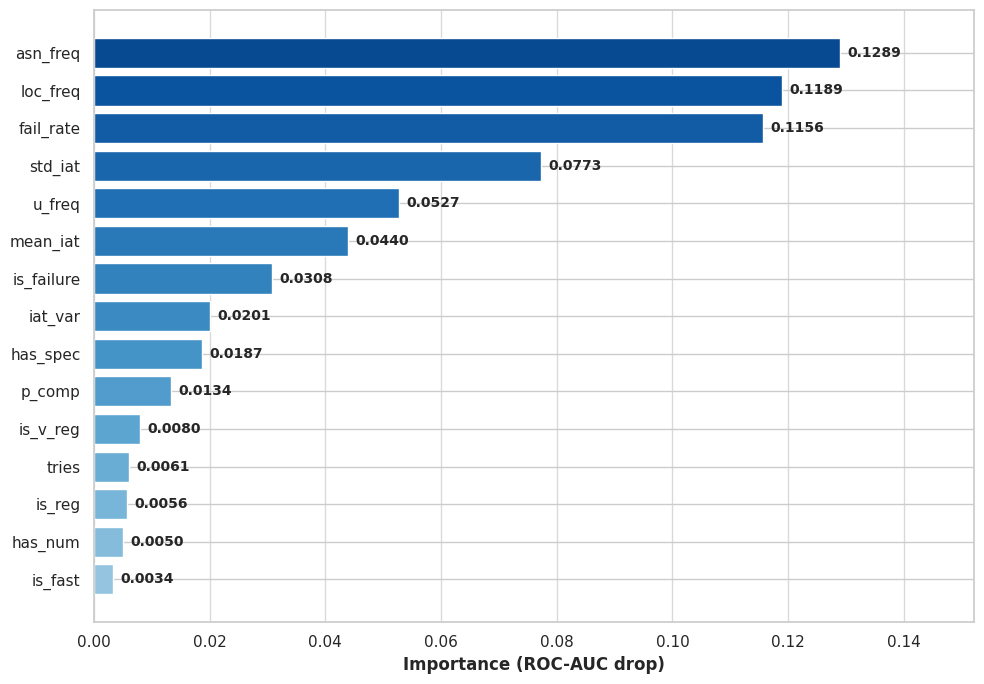

In [24]:
rng = np.random.RandomState(SEED)
pos = rng.choice(len(X_val_scaled), size=min(30000, len(X_val_scaled)), replace=False)
Xv = X_val_scaled.iloc[pos].values.astype("float32")
yv = y_val.iloc[pos].values

base_auc = roc_auc_score(yv, dnn.predict(Xv, batch_size=4096, verbose=0).ravel())

drops = np.zeros(Xv.shape[1])
repeats = 3
for j in range(Xv.shape[1]):
    for _ in range(repeats):
        Xp = Xv.copy()
        Xp[:, j] = rng.permutation(Xp[:, j])
        auc_j = roc_auc_score(yv, dnn.predict(Xp, batch_size=4096, verbose=0).ravel())
        drops[j] += (base_auc - auc_j) / repeats

top_features = pd.DataFrame({
    'Feature': X_val_scaled.columns,
    'Importance': np.clip(drops, 0, None)
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 7))
top_15 = top_features.head(15)
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_15)))
bars = plt.barh(range(len(top_15)), top_15['Importance'].values, color=colors[::-1])

plt.grid(visible=True, axis='x', color='black', linestyle='-', alpha=0.15)
plt.yticks(range(len(top_15)), top_15['Feature'].values)
plt.xlabel('Importance (ROC-AUC drop)', fontsize=12, fontweight='bold')
plt.gca().invert_yaxis()
plt.xlim(0, top_15['Importance'].max() * 1.18)
for i, (bar, val) in enumerate(zip(bars, top_15['Importance'].values)):
    plt.text(
        bar.get_width() + (top_15['Importance'].max() * 0.01),
        bar.get_y() + bar.get_height()/2,
        f'{val:.4f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

17. Classification Report

In [25]:
report_dict = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report_dict).transpose()

for col in ['precision', 'recall', 'f1-score']:
    df_report[col] = df_report[col].apply(lambda x: f"{x*100:.2f}%")

display(df_report)

,precision,recall,f1-score,support
Normal,82.05%,76.53%,79.19%,67021.000000
Attack,71.91%,78.21%,74.92%,51491.000000
accuracy,77.26%,77.26%,77.26%,0.772563
macro avg,76.98%,77.37%,77.06%,118512.000000
weighted avg,77.64%,77.26%,77.34%,118512.000000


18. Pearson Correlation Matrix

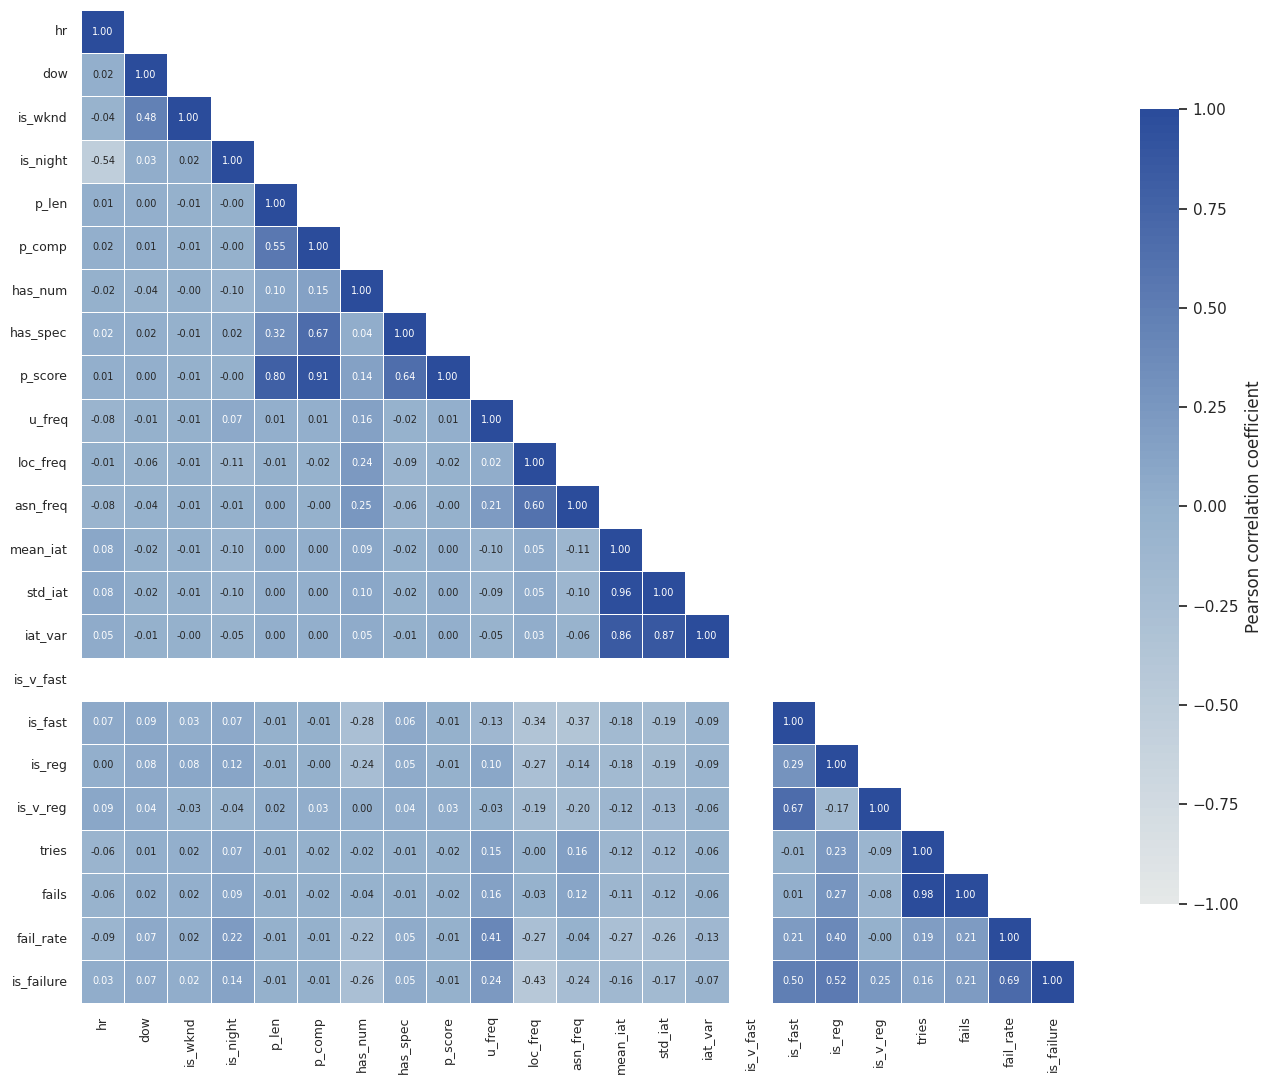

,Feature 1,Feature 2,Pearson r
0,fails,tries,0.984
1,std_iat,mean_iat,0.965
2,p_score,p_comp,0.906
3,iat_var,std_iat,0.869
4,iat_var,mean_iat,0.859
5,p_score,p_len,0.795
6,is_failure,fail_rate,0.695
7,has_spec,p_comp,0.674
8,is_v_reg,is_fast,0.667
9,p_score,has_spec,0.641


In [26]:
corr_matrix = X_train.corr(method="pearson", numeric_only=True)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

colors = ["#E5E8E8", "#94B0CC", "#2B4C9B"]
custom_cmap = LinearSegmentedColormap.from_list("gray_to_blue", colors, N=100)

plt.figure(figsize=(14, 11))
sns.set_style("white")
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap=custom_cmap,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Pearson correlation coefficient", "shrink": 0.8}
)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

pairs = (
    corr_matrix.where(~mask & (np.eye(len(corr_matrix)) == 0))
    .stack()
    .reset_index()
)
pairs.columns = ["Feature 1", "Feature 2", "Pearson r"]
pairs["abs r"] = pairs["Pearson r"].abs()
top_pairs = pairs.sort_values("abs r", ascending=False).drop(columns="abs r").head(15).reset_index(drop=True)
top_pairs["Pearson r"] = top_pairs["Pearson r"].round(3)
top_pairs

19. Confusion Matrix

3704/3704 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step


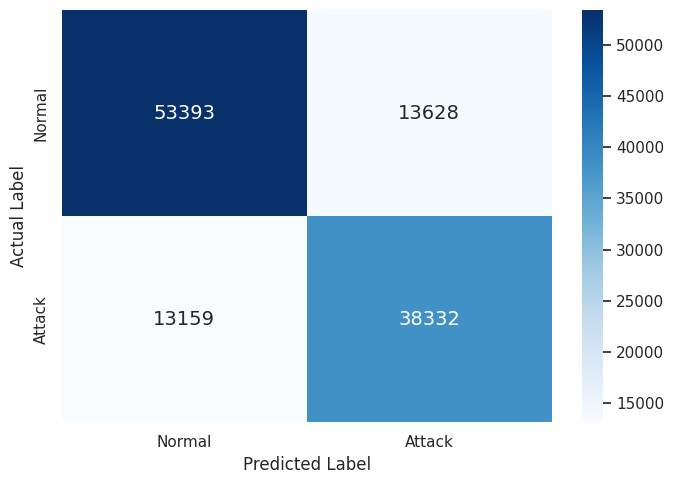

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = (dnn.predict(X_test_dnn) >= 0.5).astype(int).ravel()

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"],
    annot_kws={"size": 14}
)


plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.tight_layout()
plt.savefig("DNN_Confusion_Matrix.png", dpi=600, bbox_inches="tight")
plt.show()

3704/3704 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step


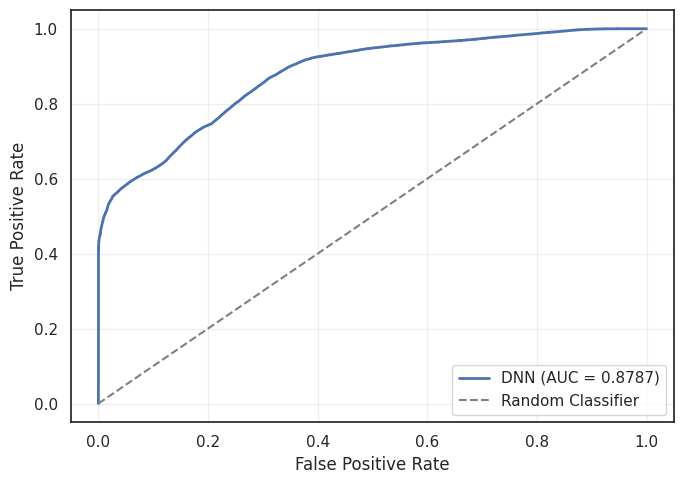

ROC-AUC: 0.8787


In [30]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_score = dnn.predict(X_test_dnn).ravel()

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_score,
    pos_label=1
)

auc_value = roc_auc_score(y_test, y_score)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"DNN (AUC = {auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("DNN_ROC_Curve.png", dpi=600, bbox_inches="tight")
plt.show()

print("ROC-AUC:", round(auc_value, 4))

20. Classification Report Heatmap

In [ ]:
report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).iloc[:-1, :3].T

plt.figure(figsize=(10, 5))
sns.heatmap(report_df, annot=True, fmt=".3f",
            cmap="Blues", annot_kws={"size": 14, "weight": "bold"})
plt.tight_layout()
plt.show()

21. Operational Performance and Security Metrics

In [ ]:
attack_recall = report['Attack']['recall']
normal_recall = report['Normal']['recall']

detection_rate = attack_recall * 100
far_rate = (1 - normal_recall) * 100

fig, ax1 = plt.subplots(figsize=(7, 5))

metrics = ['Detection Rate', 'False Alarm Rate']
values = [detection_rate, far_rate]

ax1.bar(metrics, values, color=['#2ECC71', '#E74C3C'])

ax1.set_ylim(0, 115)
ax1.set_ylabel('Percentage (%)', fontweight='bold')

for i, v in enumerate(values):
    ax1.text(i, v + 3, f"{v:.2f}%", ha='center', fontweight='bold')

plt.show()

XAI- SHAP and LIME

22. SHAP Explanation

In [ ]:
def predict_2d(X):
    X = np.asarray(X, dtype="float32")
    return dnn.predict(X, batch_size=4096, verbose=0).ravel()

rng = np.random.RandomState(42)
idx = rng.choice(len(X_test), size=min(300, len(X_test)), replace=False)
X_sample_for_explainer = X_test.iloc[idx]
X_sample_scaled = X_test_scaled.iloc[idx]
feature_names_list = X_test.columns.tolist()

background = X_train_scaled.sample(n=100, random_state=42).values

print("SHAP Explanation (DNN):")
explainer = shap.Explainer(
    predict_2d,
    shap.maskers.Independent(background, max_samples=50),
    algorithm="permutation"
)
shap_values = explainer(X_sample_scaled.values, max_evals=100)

sv = np.array(shap_values.values).reshape(len(idx), len(FEATURES))

shap_values_class_1 = sv
shap_values_class_0 = -sv
print(f"SHAP values shape: {sv.shape}")

23. SHAP Beeswarm Plots

In [ ]:
print("Class 0 (Normal)")
shap.summary_plot(
    shap_values_class_0,
    X_sample_for_explainer,
    feature_names=feature_names_list,
    max_display=10,
    plot_type="dot",
    plot_size=(10, 6),
    show=False
)
plt.grid(True, linestyle='--', alpha=0.3, color='gray')
plt.tight_layout()
plt.show()

print("Class 1 (Attack)")
shap.summary_plot(
    shap_values_class_1,
    X_sample_for_explainer,
    feature_names=feature_names_list,
    max_display=10,
    plot_type="dot",
    plot_size=(10, 6),
    show=False
)
plt.grid(True, linestyle='--', alpha=0.3, color='gray')
plt.tight_layout()
plt.show()

24. SHAP Global Feature Importance

In [ ]:
importance_all = np.mean(np.abs(sv), axis=0)

all_indices = np.arange(len(importance_all))
mask = importance_all > 0.0001
filtered_indices = all_indices[mask]
importance = importance_all[mask]

feature_names = np.array(feature_names_list)[filtered_indices]

indices_sorted = np.argsort(importance)[::-1]
labels_for_plot = feature_names[indices_sorted].tolist()
importance_sorted = importance[indices_sorted]

plt.figure(figsize=(7, 5))

top_n = len(labels_for_plot)
colors = plt.cm.Blues(np.linspace(0.4, 0.9, top_n))

bars = plt.barh(range(top_n), importance_sorted, color=colors[::-1])
plt.yticks(range(top_n), labels_for_plot, fontsize=8.5)
plt.xlabel('mean(|SHAP value|)', fontsize=12, fontweight='bold')
plt.gca().invert_yaxis()
plt.xlim(0, importance_sorted.max() * 1.3)

for spine in plt.gca().spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color('black')

for bar, val in zip(bars, importance_sorted):
    plt.text(bar.get_width() + (importance_sorted.max() * 0.02),
             bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

shap_importance_df = pd.DataFrame({
    'Feature': labels_for_plot,
    'mean(|SHAP value|)': importance_sorted.round(4)
})
print(shap_importance_df.to_string(index=False))

25. LIME Explanation

In [ ]:
print("LIME EXPLANATION (DNN):")

lime_feature_names = X_train_scaled.columns.tolist()

def predict_proba_lime(X_input):
    X_input = np.atleast_2d(np.array(X_input, dtype="float32"))
    p = dnn.predict(X_input, batch_size=4096, verbose=0).ravel()
    return np.column_stack([1 - p, p])

lime_background = X_train_scaled.sample(n=min(20000, len(X_train_scaled)), random_state=42).values

explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=lime_background,
    feature_names=lime_feature_names,
    class_names=class_names,
    mode='classification',
    discretize_continuous=False,
    random_state=42
)

rng = np.random.RandomState(42)
sample_idx = int(rng.randint(0, len(X_test_scaled)))
sample_values_for_lime = X_test_scaled.iloc[sample_idx].values

pred_probs = predict_proba_lime(sample_values_for_lime)
pred_class_idx = int(pred_probs[0, 1] >= thr)
pred_class_name = class_names[pred_class_idx]
confidence = pred_probs[0][pred_class_idx]

true_label = int(y_test.iloc[sample_idx])
true_label_name = class_names[true_label]

exp = explainer_lime.explain_instance(
    data_row=sample_values_for_lime,
    predict_fn=predict_proba_lime,
    num_features=10,
    labels=(pred_class_idx,)
)
label_from_lime = pred_class_idx

print(f"\nSelected sample: {sample_idx}")
print(f"True label: {true_label_name}")
print(f"Model predicted: {pred_class_name} (confidence: {confidence:.3f})")
print(f"LIME explaining class: {class_names[label_from_lime]}")

if true_label != pred_class_idx:
    print("MISCLASSIFICATION!")

print("\nFeature Contributions:")
for feature, weight in exp.as_list(label=label_from_lime):
    print(f"{feature:35} -> {weight:+.4f}")

fig = exp.as_pyplot_figure(label=label_from_lime)
plt.title(
    f"LIME Explanation - Sample {sample_idx}\nTrue: {true_label_name} | Pred: {pred_class_name}",
    fontsize=12,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

26. Final Summary with All Metrics

In [ ]:
start_time = time.time()
dnn.predict(X_test_dnn, batch_size=4096, verbose=0)
end_time = time.time()
inference_speed = (end_time - start_time) / len(X_test_dnn)

far_rate_ratio = 1 - normal_recall

print("\n" + "=" * 70)
print("FINAL SUMMARY - ALL METRICS")
print("=" * 70)

print(f"""╔══════════════════════════════════════════════════════════╗
║                 MODEL PERFORMANCE SUMMARY                ║
╠══════════════════════════════════════════════════════════╣
║
║  ACCURACY:
║  • Training: {train_acc:.2%}
║  • Test: {test_acc:.2%}
║  • Validation: {val_acc:.2%}
║
║  SECURITY METRICS:
║  • Attack Detection Rate (Recall): {attack_recall:.2%}
║  • False Alarm Rate: {far_rate_ratio:.2%}
║  • System Reliability (Attack Precision): {report['Attack']['precision']:.2%}
║
║  MODEL EFFICIENCY:
║  • Overall Accuracy: {test_acc:.2%}
║  • F1-Score (Weighted): {test_f1:.2%}
║  • Inference Speed: {inference_speed*1000:.4f} ms/sample
║
║  PER-CLASS F1-SCORES:
║  • Normal: {report['Normal']['f1-score']:.2%}
║  • Attack: {report['Attack']['f1-score']:.2%}
║
║  TOP FEATURES INFLUENCING DETECTION:
║  1. {top_features.iloc[0]['Feature']}
║  2. {top_features.iloc[1]['Feature']}
║  3. {top_features.iloc[2]['Feature']}
║
║  DATA DISTRIBUTION:
║  • Total samples: {len(df)}
║  • Features used: {len(X_train.columns)}
║  • Train/Test/Val: {len(X_train)}/{len(X_test)}/{len(X_val)}
║
╚══════════════════════════════════════════════════════════╝
""")